# M1 — Extração Local de Texto (PyMuPDF + OCR)

Lê os documentos de `data/documento_social/01.arquivos_originais/` e produz, para cada um, um JSON de tokens com bounding box por página — o contrato que `notebooks/03.align_ground_truth.ipynb` espera:
```json
{"document_id": "...", "pages": [{"page": 1, "tokens": [{"text": "João", "bbox": [x0, y0, x1, y1]}]}]}
```
Bbox sempre em **pontos PDF** (72 dpi), independente da origem (texto nativo ou OCR), para manter um único referencial de coordenadas em todo o pipeline. Saída em `data/documento_social/03.extracao_ocr_local/`.

**Estratégia por página** (ver PRD.md, seções 7 e 8.1):
1. Página com camada de texto nativa → extração direta via PyMuPDF (`page.get_text("words")`), rápida e exata.
2. Página sem texto (scan puro) → renderiza em imagem, aplica pré-processamento OpenCV (deskew, denoise, threshold adaptativo), roda OCR (PaddleOCR) e converte os bbox de pixel para pontos PDF.

No dataset real atual, 4 dos 10 documentos são scan puro (ver anotacoes/anotacoes.txt, 2026-09-09) — os dois caminhos são necessários desde já, não dá pra adiar o OCR.

**⚠️ Este notebook roda em um ambiente Python ISOLADO do resto do projeto (`.venv_ocr`, Python 3.10).** O stack de OCR (`paddlepaddle-gpu`/`paddleocr`/`paddlex` + `opencv`) é pesado, exige uma wheel GPU específica (não vem do PyPI) e **não pode coexistir no mesmo venv com torch/transformers/modelscope** (conflito de cuDNN, `OSError WinError 127` no Windows) — por isso fica isolado em `requirements_ocr.txt`, nunca junto do `requirements.txt` geral. Ver o cabeçalho de `requirements_ocr.txt` para o racional completo. Setup:

```
py -3.10 -m venv .venv_ocr
.venv_ocr\Scripts\python.exe -m pip install https://paddle-qa.bj.bcebos.com/paddle-pipeline/Develop-TagBuild-Training-Windows-Gpu-Cuda12.9-Cudnn9.9-Trt10.5-Mkl-Avx-VS2019-SelfBuiltPypiUse/86d658f56ebf3a5a7b2b33ace48f22d10680d311/paddlepaddle_gpu-3.0.0.dev20250717-cp310-cp310-win_amd64.whl
.venv_ocr\Scripts\python.exe -m pip install -r requirements_ocr.txt
.venv_ocr\Scripts\python.exe -m ipykernel install --user --name locscan-ocr
```

Depois, ao abrir este notebook, selecione o kernel **`locscan-ocr`** (não o venv geral do projeto) antes de rodar as células.

**Nota de compatibilidade (achado nesta sessão):** PaddleOCR 3.7 + PaddlePaddle 3.3.1 (build CPU) quebra com `NotImplementedError` no backend oneDNN/PIR ao rodar `predict()`. Correção aplicada: instanciar com `enable_mkldnn=False`. Ainda não confirmado se esse workaround é necessário também com a build GPU (`paddlepaddle-gpu` dev20250717) — testar e remover o flag se não for mais preciso. A célula do motor OCR, abaixo, imprime se o Paddle detecta CUDA disponível (confirmado funcionando: CUDA=True, 1 GPU).

In [1]:
import os
os.environ.setdefault("FLAGS_use_mkldnn", "0")

import json
from pathlib import Path

import cv2
import numpy as np
import pymupdf

## Configuração de caminhos

In [2]:
def encontrar_raiz_projeto(marcador: str = "requirements.txt") -> Path:
    p = Path.cwd()
    for _ in range(6):
        if (p / marcador).exists():
            return p
        p = p.parent
    raise RuntimeError(f"Não encontrei a raiz do projeto ({marcador}) subindo a partir de {Path.cwd()}")

RAIZ = encontrar_raiz_projeto()

# Documentos reais e sintéticos ficam em subpastas distintas — juntamos as duas listas ao processar
# (documentos sintéticos, gerados por notebooks/00.gerar_documentos_sinteticos.ipynb, já têm o JSON
# de extração pronto direto naquele notebook — a checagem SOBRESCREVER abaixo já pula eles automaticamente).
PASTA_ENTRADA_REAIS = RAIZ / "data" / "documento_social" / "01.arquivos_originais" / "arquivos_reais"
PASTA_ENTRADA_SINTETICOS = RAIZ / "data" / "documento_social" / "01.arquivos_originais" / "arquivos_sinteticos"
PASTA_SAIDA = RAIZ / "data" / "documento_social" / "03.extracao_ocr_local"
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

DPI_RENDER = 300           # resolução de renderização para páginas sem texto nativo
MIN_CHARS_TEXTO_NATIVO = 20  # abaixo disso, trata a página como scan mesmo se PyMuPDF achar algo
MIN_SPREAD_VERTICAL_TEXTO_NATIVO = 0.30  # texto nativo precisa cobrir >=30% da altura da página
                                          # (senão é provavelmente só selo/carimbo de autenticação
                                          # sobre um corpo escaneado — ver tem_texto_nativo() abaixo)
MIN_RATIO_LEGIVEL_TEXTO_NATIVO = 0.70    # fração mínima de caracteres "normais" no texto nativo
                                          # (senão é provavelmente fonte customizada/encoding
                                          # quebrado no PDF — ver tem_texto_nativo() abaixo)
SOBRESCREVER = False

EXTENSOES_PDF = {".pdf"}
EXTENSOES_IMAGEM = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"}

print(f"Raiz do projeto: {RAIZ}")
print(f"Entrada (reais):      {PASTA_ENTRADA_REAIS}")
print(f"Entrada (sintéticos): {PASTA_ENTRADA_SINTETICOS}")
print(f"Saída:   {PASTA_SAIDA}")

Raiz do projeto: d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3
Entrada (reais):      d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\data\documento_social\01.arquivos_originais\arquivos_reais
Entrada (sintéticos): d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\data\documento_social\01.arquivos_originais\arquivos_sinteticos
Saída:   d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\data\documento_social\03.extracao_ocr_local


## Pré-processamento de imagem (OpenCV)

Sequência determinística (mesmos bytes de entrada → mesmos pixels de saída, ver PRD.md seção NFR3): deskew (correção de inclinação via transformada de Hough) → denoising (fastNlMeansDenoising, moderado para não borrar dígitos finos) → binarização adaptativa (lida bem com sombras/iluminação irregular de documento fotografado/escaneado).

In [3]:
def corrigir_inclinacao(img_cinza: np.ndarray) -> np.ndarray:
    """Detecta o ângulo dominante do texto via Hough e rotaciona para nivelar a página."""
    bordas = cv2.Canny(img_cinza, 50, 150, apertureSize=3)
    linhas = cv2.HoughLinesP(bordas, 1, np.pi / 180, threshold=200, minLineLength=img_cinza.shape[1] // 4, maxLineGap=20)

    if linhas is None or len(linhas) == 0:
        return img_cinza

    angulos = []
    for linha in linhas:
        x1, y1, x2, y2 = linha[0]
        angulo = np.degrees(np.arctan2(y2 - y1, x2 - x1))
        if -45 < angulo < 45:  # ignora linhas quase verticais (bordas, tabelas)
            angulos.append(angulo)

    if not angulos:
        return img_cinza

    angulo_mediano = float(np.median(angulos))
    if abs(angulo_mediano) < 0.3:  # já está praticamente reto, não vale rotacionar
        return img_cinza

    h, w = img_cinza.shape[:2]
    centro = (w // 2, h // 2)
    matriz = cv2.getRotationMatrix2D(centro, angulo_mediano, 1.0)
    return cv2.warpAffine(img_cinza, matriz, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)


def preprocessar_imagem(img_bgr: np.ndarray) -> np.ndarray:
    """Pipeline determinístico: escala de cinza -> deskew -> denoise moderado -> threshold adaptativo.
    Retorna imagem binarizada (preto/branco) pronta para OCR."""
    cinza = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    cinza = corrigir_inclinacao(cinza)
    # denoise moderado (h baixo) para não apagar traços finos de dígitos
    cinza = cv2.fastNlMeansDenoising(cinza, h=7, templateWindowSize=7, searchWindowSize=21)
    binarizada = cv2.adaptiveThreshold(
        cinza, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, blockSize=31, C=15
    )
    return binarizada

## Motor OCR (PaddleOCR)

In [4]:
import paddle
from paddleocr import PaddleOCR

cuda_disponivel = paddle.device.is_compiled_with_cuda()
n_gpus = paddle.device.cuda.device_count() if cuda_disponivel else 0
print(f"Paddle compilado com CUDA: {cuda_disponivel} | GPUs detectadas: {n_gpus}")
if not cuda_disponivel:
    print("-> Rodando em CPU. Para usar a RTX 5060 Ti, ver nota de GPU em requirements_ocr.txt "
          "(NÃO instale paddlepaddle-gpu sem desinstalar paddlepaddle antes).")

OCR = PaddleOCR(
    device="gpu:0", 
    lang="pt",
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
    return_word_box=True,
    enable_mkldnn=False,  # ver nota de compatibilidade na introdução
)

d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\.venv_ocr\lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:717: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
d:\Arquivos\ProjetosPython\BFC\LocalScanDocument_v3\.venv_ocr\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\Gabriel-PC\.paddlex\official_models\PP-OCRv6_medium_det`.


Paddle compilado com CUDA: True | GPUs detectadas: 1


Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\Gabriel-PC\.paddlex\official_models\PP-OCRv6_medium_rec`.


## Extração por página: nativa ou OCR

In [ ]:
def extrair_pagina_nativa(pagina: "pymupdf.Page") -> list:
    """Tokens a partir da camada de texto nativa do PDF, bbox já em pontos PDF."""
    palavras = pagina.get_text("words")  # (x0, y0, x1, y1, texto, block_no, line_no, word_no)
    tokens = []
    for x0, y0, x1, y1, texto, *_ in palavras:
        texto = texto.strip()
        if texto:
            tokens.append({"text": texto, "bbox": [round(x0, 2), round(y0, 2), round(x1, 2), round(y1, 2)]})
    return tokens


def _box_para_bbox(box) -> list:
    """Converte o box retornado pelo PaddleOCR (text_word_boxes) para [x0, y0, x1, y1].

    O PaddleOCR retorna, por palavra, ou um array 1D já no formato [x0, y0, x1, y1]
    (comum quando a linha tem só uma palavra), ou um array 2D com os cantos do
    polígono (várias linhas [x, y]) — tratamos os dois casos."""
    box = np.asarray(box, dtype=float)
    if box.ndim == 1:
        x0, y0, x1, y1 = box[:4]
        return [float(x0), float(y0), float(x1), float(y1)]
    xs = box[:, 0]
    ys = box[:, 1]
    return [float(xs.min()), float(ys.min()), float(xs.max()), float(ys.max())]


def mesclar_tokens_fragmentados(tokens: list) -> list:
    """Junta tokens que o PaddleOCR partiu incorretamente no meio de uma palavra.

    Achado na investigação de erros do NER (anotacoes.txt, 2026-09-11): acentos (é, á, ã...)
    às vezes saem como um "token" isolado, separado do resto da palavra por uma lacuna muito
    menor que o espaço real entre palavras — ex. "José" saindo como "Jos" + "é". Isso corrompe
    o bbox da entidade e faz a avaliação por IoU falhar mesmo quando o texto reconhecido está
    certo. Critério de fusão: token seguinte com <= 2 caracteres, não iniciando em maiúscula
    (não é sigla/abreviação legítima), na mesma linha, com lacuna horizontal bem menor que a
    altura da linha (gap real de espaço entre palavras é proporcionalmente maior)."""
    if not tokens:
        return tokens
    tokens_ordenados = sorted(tokens, key=lambda t: (round(t["bbox"][1], 0), t["bbox"][0]))
    mesclados = [dict(tokens_ordenados[0])]
    for tok in tokens_ordenados[1:]:
        anterior = mesclados[-1]
        altura_ref = max(anterior["bbox"][3] - anterior["bbox"][1], 1.0)
        mesma_linha = abs(tok["bbox"][1] - anterior["bbox"][1]) < altura_ref * 0.5
        gap = tok["bbox"][0] - anterior["bbox"][2]
        fragmento_isolado = len(tok["text"]) <= 2 and not tok["text"][:1].isupper()
        if mesma_linha and fragmento_isolado and 0 <= gap < altura_ref * 0.35:
            anterior["text"] = anterior["text"] + tok["text"]
            anterior["bbox"][2] = tok["bbox"][2]
            anterior["bbox"][1] = min(anterior["bbox"][1], tok["bbox"][1])
            anterior["bbox"][3] = max(anterior["bbox"][3], tok["bbox"][3])
        else:
            mesclados.append(dict(tok))
    return mesclados


def _dpi_efetivo_pagina(pagina, dpi_padrao: int = DPI_RENDER, cobertura_minima: float = 0.75) -> int:
    """Calcula o DPI que reproduz a resolução NATIVA da imagem escaneada dominante da página, em
    vez de sempre usar `dpi_padrao` fixo. Achado 2026-09-21: alguns PDFs escaneados declaram um
    MediaBox bem maior que o conteúdo real (ex.: scan A4 dentro de um MediaBox de ~21x30
    polegadas -- "Constituição 12-09-1996.pdf" do holdout). Nesses casos, `get_pixmap(dpi=300)`
    faz o PyMuPDF esticar/interpolar a imagem original (resolução fixa) sobre uma área bem maior
    que a real, produzindo uma imagem "borrada" com MENOS densidade de informação por área do que
    o DPI nominal sugere -- e o OCR sai pior nessas páginas. Usar o DPI calculado a partir da
    proporção real (pixels nativos da imagem / tamanho do bbox onde ela está desenhada) evita
    essa interpolação: quando o resultado é MENOR que `dpi_padrao`, ainda assim reproduz a imagem
    de forma mais fiel (praticamente 1:1, sem esticar) do que insistir no DPI fixo sobre uma
    página maior que o conteúdo real."""
    try:
        # Regressão real encontrada 2026-09-21 (documento "Alteração Consolidada 102019.pdf",
        # páginas 2/5/6/7): páginas com uma imagem de fundo quase em branco (papel de segurança/
        # marca d'água) cobrindo quase toda a área, mas com o conteúdo de verdade em TEXTO NATIVO
        # por cima -- calcular um DPI baseado só na imagem, nesse caso, é inofensivo aqui (esta
        # função só decide o DPI do get_pixmap, que sempre compõe texto+imagem corretamente), mas
        # ainda assim não faz sentido recalcular DPI a partir de uma imagem de fundo decorativa
        # quando a página tem texto nativo de verdade -- usa o DPI padrão nesse caso.
        if len(pagina.get_text().strip()) >= 20:
            return dpi_padrao
        area_pagina = pagina.rect.width * pagina.rect.height
        if area_pagina <= 0:
            return dpi_padrao
        melhor_bbox, melhor_area, melhor_largura_px = None, 0, None
        for info in pagina.get_image_info(xrefs=True):
            bbox = info.get("bbox")
            if not bbox:
                continue
            area_imagem = (bbox[2] - bbox[0]) * (bbox[3] - bbox[1])
            if area_imagem > melhor_area:
                melhor_area, melhor_bbox, melhor_largura_px = area_imagem, bbox, info.get("width")
        if melhor_bbox is None or not melhor_largura_px or (melhor_area / area_pagina) < cobertura_minima:
            return dpi_padrao
        largura_bbox_pt = melhor_bbox[2] - melhor_bbox[0]
        if largura_bbox_pt <= 0:
            return dpi_padrao
        return max(72, round((melhor_largura_px / largura_bbox_pt) * 72))
    except Exception:
        return dpi_padrao


def extrair_pagina_ocr(pagina: "pymupdf.Page", dpi: int = DPI_RENDER) -> list:
    """Renderiza a página, pré-processa e roda OCR. Bbox convertido de pixel para pontos PDF."""
    dpi = _dpi_efetivo_pagina(pagina, dpi)
    pix = pagina.get_pixmap(dpi=dpi)
    img = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
    if pix.n == 4:
        img_bgr = cv2.cvtColor(img, cv2.COLOR_RGBA2BGR)
    else:
        img_bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)

    img_processada = preprocessar_imagem(img_bgr)
    img_ocr = cv2.cvtColor(img_processada, cv2.COLOR_GRAY2BGR)  # PaddleOCR espera 3 canais

    resultado = OCR.predict(img_ocr)
    if not resultado:
        return []
    r = resultado[0]

    escala = 72.0 / dpi  # pixel -> ponto PDF
    tokens = []

    palavras_por_linha = r.get("text_word", [])
    boxes_por_linha = r.get("text_word_boxes", [])

    for palavras_linha, boxes_linha in zip(palavras_por_linha, boxes_por_linha):
        tokens_linha = []
        for palavra, box in zip(palavras_linha, boxes_linha):
            palavra = palavra.strip()
            if not palavra:
                continue
            x0, y0, x1, y1 = _box_para_bbox(box)
            tokens_linha.append({
                "text": palavra,
                "bbox": [round(x0 * escala, 2), round(y0 * escala, 2), round(x1 * escala, 2), round(y1 * escala, 2)],
            })
        tokens.extend(mesclar_tokens_fragmentados(tokens_linha))

    return tokens

## Triagem e processamento de um documento completo

In [ ]:
def _ratio_caracteres_legiveis(texto: str) -> float:
    """Fração de caracteres 'normais' (letra, dígito, espaço, pontuação comum) no texto.

    PDFs com fonte customizada/sem ToUnicode válido fazem o PyMuPDF extrair os códigos
    de glifo crus como se fossem caracteres Unicode — na prática, uma sopa de caracteres
    de controle (\\x00-\\x1f) e símbolos sem sentido. Isso é DIFERENTE de não ter texto
    nativo: a página passa nos critérios de quantidade/spread, mas o conteúdo é lixo.
    Calibrado empiricamente (ver anotacoes/anotacoes.txt, 2026-09-09): páginas com fonte
    quebrada ficam por volta de 0.43-0.62; uma página com texto nativo legítimo fica
    acima de 0.75."""
    if not texto:
        return 0.0
    validos = sum(1 for c in texto if c.isalpha() or c.isdigit() or c.isspace() or c in ".,;:-/()ºª%")
    return validos / len(texto)


def tem_texto_nativo(pagina: "pymupdf.Page") -> bool:
    """Decide se a página tem corpo de texto nativo real e legível, ou se deve ir para OCR.

    Três filtros, todos precisam passar:
    1) Quantidade mínima de caracteres (MIN_CHARS_TEXTO_NATIVO) — descarta páginas vazias.
    2) Spread vertical mínimo (MIN_SPREAD_VERTICAL_TEXTO_NATIVO) — descarta páginas onde o
       "texto nativo" é só um selo/carimbo de autenticação confinado a uma faixa estreita
       (comum em documentos da Junta Comercial), com o corpo real sendo uma imagem escaneada
       por baixo.
    3) Legibilidade mínima (MIN_RATIO_LEGIVEL_TEXTO_NATIVO) — descarta páginas cujo texto
       nativo é ilegível por causa de fonte customizada/encoding quebrado no PDF (o texto
       "existe" e se espalha pela página, mas é uma sopa de caracteres de controle/símbolos).
    Qualquer um desses filtros reprovando manda a página para o caminho de OCR."""
    texto = pagina.get_text().strip()
    if len(texto) < MIN_CHARS_TEXTO_NATIVO:
        return False

    if _ratio_caracteres_legiveis(texto) < MIN_RATIO_LEGIVEL_TEXTO_NATIVO:
        return False

    palavras = pagina.get_text("words")
    if not palavras:
        return False

    altura_pagina = pagina.rect.height
    if altura_pagina <= 0:
        return True

    ys = [w[1] for w in palavras]  # y0 de cada palavra
    spread_relativo = (max(ys) - min(ys)) / altura_pagina
    return spread_relativo >= MIN_SPREAD_VERTICAL_TEXTO_NATIVO


def processar_pdf(caminho: Path) -> dict:
    doc = pymupdf.open(str(caminho))
    paginas_saida = []

    for i, pagina in enumerate(doc, start=1):
        if tem_texto_nativo(pagina):
            tokens = extrair_pagina_nativa(pagina)
            metodo = "nativo"
        else:
            tokens = extrair_pagina_ocr(pagina)
            metodo = "ocr"
        paginas_saida.append({"page": i, "method": metodo, "tokens": tokens})

    doc.close()
    return {"document_id": caminho.stem, "source_file": caminho.name, "pages": paginas_saida}


def processar_imagem(caminho: Path) -> dict:
    img_bgr = cv2.imread(str(caminho))
    img_processada = preprocessar_imagem(img_bgr)
    img_ocr = cv2.cvtColor(img_processada, cv2.COLOR_GRAY2BGR)

    resultado = OCR.predict(img_ocr)
    tokens = []
    if resultado:
        r = resultado[0]
        for palavras_linha, boxes_linha in zip(r.get("text_word", []), r.get("text_word_boxes", [])):
            tokens_linha = []
            for palavra, box in zip(palavras_linha, boxes_linha):
                palavra = palavra.strip()
                if not palavra:
                    continue
                x0, y0, x1, y1 = _box_para_bbox(box)
                tokens_linha.append({"text": palavra, "bbox": [round(x0, 2), round(y0, 2), round(x1, 2), round(y1, 2)]})
            tokens.extend(mesclar_tokens_fragmentados(tokens_linha))

    # imagem solta = documento de 1 página; bbox em pixels da própria imagem (sem PDF de referência)
    return {"document_id": caminho.stem, "source_file": caminho.name, "pages": [{"page": 1, "method": "ocr", "tokens": tokens}]}

## Loop principal

In [7]:
def listar_arquivos_suportados(pasta: Path) -> list:
    if not pasta.is_dir():
        return []
    return [p for p in pasta.iterdir() if p.is_file() and p.suffix.lower() in (EXTENSOES_PDF | EXTENSOES_IMAGEM)]


arquivos = sorted(listar_arquivos_suportados(PASTA_ENTRADA_REAIS) + listar_arquivos_suportados(PASTA_ENTRADA_SINTETICOS))

if not arquivos:
    raise SystemExit(f"Nenhum arquivo suportado encontrado em {PASTA_ENTRADA_REAIS} ou {PASTA_ENTRADA_SINTETICOS}")

print(f"Encontrados {len(arquivos)} arquivo(s) ({PASTA_ENTRADA_REAIS.name} + {PASTA_ENTRADA_SINTETICOS.name})")

for i, caminho in enumerate(arquivos, start=1):
    destino = PASTA_SAIDA / f"{caminho.stem}.json"
    if destino.exists() and not SOBRESCREVER:
        print(f"[{i}/{len(arquivos)}] {caminho.name}: já existe, pulando (SOBRESCREVER=True para refazer)")
        continue

    print(f"[{i}/{len(arquivos)}] {caminho.name}: processando...")
    try:
        if caminho.suffix.lower() in EXTENSOES_PDF:
            registro = processar_pdf(caminho)
        else:
            registro = processar_imagem(caminho)
    except Exception as e:
        print(f"[{i}/{len(arquivos)}] {caminho.name}: ERRO -> {e}")
        continue

    destino.write_text(json.dumps(registro, ensure_ascii=False, indent=2), encoding="utf-8")

    n_tokens = sum(len(p["tokens"]) for p in registro["pages"])
    metodos = {p["page"]: p["method"] for p in registro["pages"]}
    print(f"[{i}/{len(arquivos)}] {caminho.name}: {len(registro['pages'])} página(s), {n_tokens} token(s) | métodos: {metodos} -> {destino.name}")

print("\nConcluído.")

Encontrados 1510 arquivo(s) (arquivos_reais + arquivos_sinteticos)
[1/1510] clpif4a2h00b92pqd67v27lm9-ALTERAÇÃO 1º DA EMPRESA TL TRANSPOSTES E LOGISTICA LTDA ME.pdf.pdf: já existe, pulando (SOBRESCREVER=True para refazer)
[2/1510] clpif4mn700bb2pqde5cy04ej-INSTRUMENTO PARTICULAR 1º ALTERAÇÃO CONTRATUAL.pdf.pdf: já existe, pulando (SOBRESCREVER=True para refazer)
[3/1510] clpif4v9800bd2pqd76oa1krz-INSTRUMENTO PARTICULAR 2º ALTERAÇÃO CONTRATUAL.pdf.pdf: já existe, pulando (SOBRESCREVER=True para refazer)
[4/1510] clpif50i000bf2pqd2ky17hb4-INSTRUMENTO PARTICULAR 4 ALTERAÇÃO CONTRATUAL 11082010.pdf.pdf: já existe, pulando (SOBRESCREVER=True para refazer)
[5/1510] clrpcwgv0003gj9qd31axe84h-2ª alteração contratual consolidada.pdf.pdf: já existe, pulando (SOBRESCREVER=True para refazer)
[6/1510] cls3l2zm400a3yrqdbj1yd5px-Ata out19 - inclusão objeto social.pdf.pdf: já existe, pulando (SOBRESCREVER=True para refazer)
[7/1510] cls3l36ct00a5yrqd6mzp7c5r-Ata jan20 - inculsão objeto social.pdf.pdf:

Resized image size (4819x6848) exceeds max_side_limit of 4000. Resizing to fit within limit.


[172/1510] cm3zxmtcs008r6mqdbuhi8h9m-BRUNO MEDEIROS20012015_0014.jpg.jpg: 1 página(s), 336 token(s) | métodos: {1: 'ocr'} -> cm3zxmtcs008r6mqdbuhi8h9m-BRUNO MEDEIROS20012015_0014.jpg.json
[173/1510] cm3zxn22l008v6mqdexkih563-BRUNO MEDEIROS20012015_0016.jpg.jpg: processando...


Resized image size (4819x6848) exceeds max_side_limit of 4000. Resizing to fit within limit.


[173/1510] cm3zxn22l008v6mqdexkih563-BRUNO MEDEIROS20012015_0016.jpg.jpg: 1 página(s), 374 token(s) | métodos: {1: 'ocr'} -> cm3zxn22l008v6mqdexkih563-BRUNO MEDEIROS20012015_0016.jpg.json
[174/1510] cm3zxn8us007m6lqdeh1j99h2-BRUNO MEDEIROS20012015_0018.jpg.jpg: processando...


Resized image size (4819x6848) exceeds max_side_limit of 4000. Resizing to fit within limit.


... (13 outputs left out)

Resized image size (5705x8204) exceeds max_side_limit of 4000. Resizing to fit within limit.
Resized image size (5398x7878) exceeds max_side_limit of 4000. Resizing to fit within limit.


[744/1510] cmnen4z2w007k01ow8psl5y3t-quartaalteracaoeconsolidacaocontratualdasociedadeempresarialimitadaunipessoalpdf.pdf: 2 página(s), 1492 token(s) | métodos: {1: 'ocr', 2: 'ocr'} -> cmnen4z2w007k01ow8psl5y3t-quartaalteracaoeconsolidacaocontratualdasociedadeempresarialimitadaunipessoalpdf.json
[745/1510] cmnepiqcm000a01nthq30fbnb-certidointeiroteorltalteraokitambarartefatospdf.pdf: já existe, pulando (SOBRESCREVER=True para refazer)
[746/1510] cmnf2hkmz001301nmff59a9wi-assinado20251127171012contratopbp2504558407pdf.pdf: já existe, pulando (SOBRESCREVER=True para refazer)
[747/1510] cmnhwwla7000101o1cp8m12xf-9alteracaom2jigarrafeirabrasil1pdf.pdf: já existe, pulando (SOBRESCREVER=True para refazer)
[748/1510] cmnnbdleo002801p97wzxacj5-contratosocialnovonov2025pdf.pdf: já existe, pulando (SOBRESCREVER=True para refazer)
[749/1510] cmnneh47k003401pjhcf518qm-contratosocialquartaalteraocontratual141120241pdf.pdf: já existe, pulando (SOBRESCREVER=True para refazer)
[750/1510] cmnoqnfmf003k

Resized image size (10534x14600) exceeds max_side_limit of 4000. Resizing to fit within limit.
Resized image size (10534x14600) exceeds max_side_limit of 4000. Resizing to fit within limit.
Resized image size (10534x14600) exceeds max_side_limit of 4000. Resizing to fit within limit.
Resized image size (10534x14600) exceeds max_side_limit of 4000. Resizing to fit within limit.


[899/1510] cmrv2htaf00rj01mjbvr68jeh-4alteracaocontratualpdf.pdf: 4 página(s), 1850 token(s) | métodos: {1: 'ocr', 2: 'ocr', 3: 'ocr', 4: 'ocr'} -> cmrv2htaf00rj01mjbvr68jeh-4alteracaocontratualpdf.json
[900/1510] cmrw6hlu600uj01pkfqds2isc-processo21512537123620211749394pdf.pdf: já existe, pulando (SOBRESCREVER=True para refazer)
[901/1510] cmrw92he600vq01lc0qlhg203-1alteraocontratualconsolidadagruposonhopdf.pdf: processando...
[901/1510] cmrw92he600vq01lc0qlhg203-1alteraocontratualconsolidadagruposonhopdf.pdf: 5 página(s), 1337 token(s) | métodos: {1: 'nativo', 2: 'nativo', 3: 'nativo', 4: 'nativo', 5: 'nativo'} -> cmrw92he600vq01lc0qlhg203-1alteraocontratualconsolidadagruposonhopdf.json
[902/1510] cmrwaheov00w601lcb61e15vh-2alteracaocontratualguilhermelimaadmpdf.pdf: já existe, pulando (SOBRESCREVER=True para refazer)
[903/1510] cmrwe791b001n01o6hl1d4un4-primeiraalteracaocontratualhomologadapelajucegpdf.pdf: processando...
[903/1510] cmrwe791b001n01o6hl1d4un4-primeiraalteracaocontrat

## Conferência visual — desenha os bbox extraídos sobre a página renderizada

Sanity check essencial: confirma que os bbox (nativos e de OCR) estão de fato na posição certa, na mesma escala. Ajuste `DOC_ID` e `PAGINA` para inspecionar qualquer documento/página já processados.

Documento: clpif4a2h00b92pqd67v27lm9-ALTERAÇÃO 1º DA EMPRESA TL TRANSPOSTES E LOGISTICA LTDA ME.pdf | página 1 | método: ocr | 391 tokens


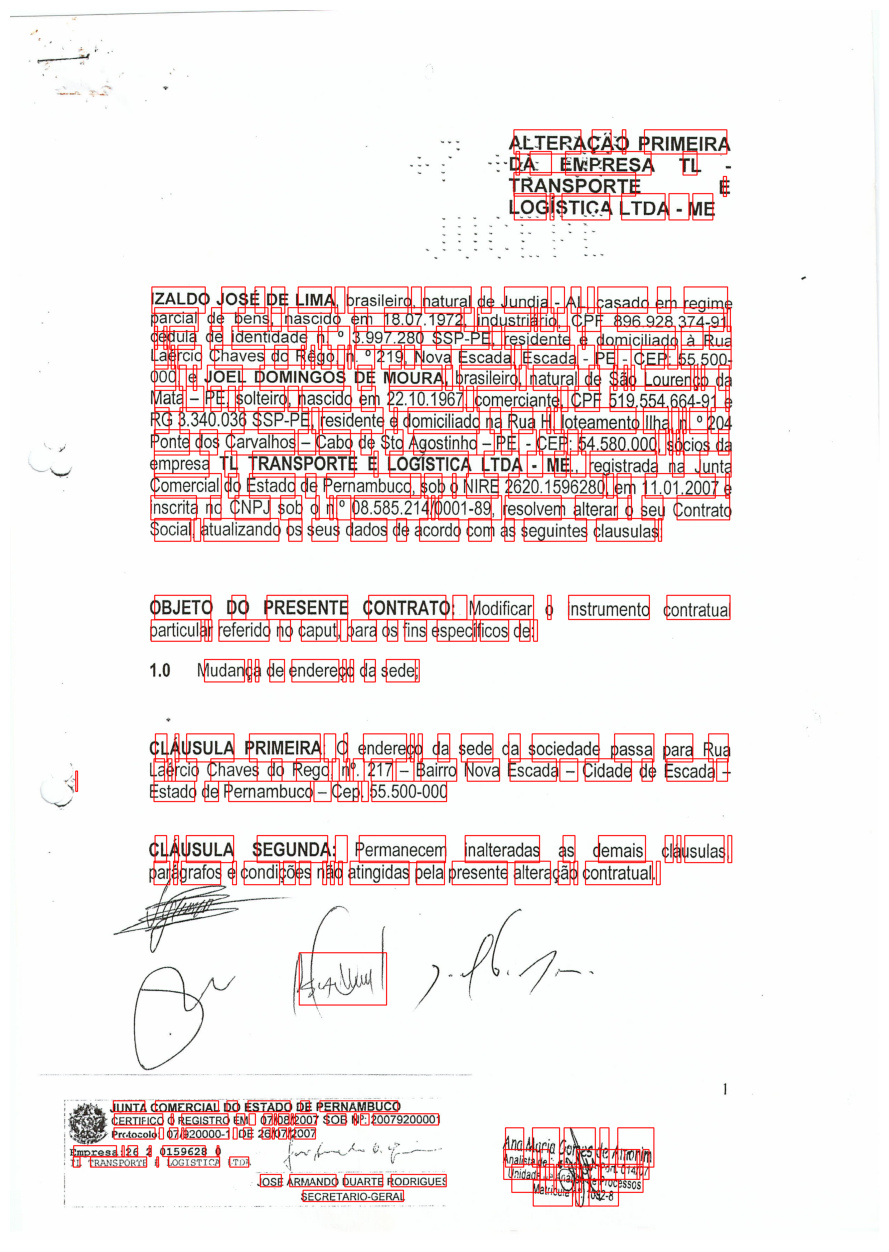

In [8]:
import matplotlib.pyplot as plt

DOC_ID = arquivos[0].stem  # troque para inspecionar outro documento
PAGINA = 1

extracao = json.loads((PASTA_SAIDA / f"{DOC_ID}.json").read_text(encoding="utf-8"))
pagina_dados = next(p for p in extracao["pages"] if p["page"] == PAGINA)

caminho_pdf = PASTA_ENTRADA_REAIS / extracao["source_file"]
if not caminho_pdf.exists():
    caminho_pdf = PASTA_ENTRADA_SINTETICOS / extracao["source_file"]
doc = pymupdf.open(str(caminho_pdf))
pix = doc[PAGINA - 1].get_pixmap(dpi=DPI_RENDER)
img = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
img_bgr = cv2.cvtColor(img, cv2.COLOR_RGBA2BGR if pix.n == 4 else cv2.COLOR_RGB2BGR)
doc.close()

escala_desenho = DPI_RENDER / 72.0  # pontos PDF -> pixels desta renderização
img_anotada = img_bgr.copy()
for tok in pagina_dados["tokens"]:
    x0, y0, x1, y1 = [c * escala_desenho for c in tok["bbox"]]
    cv2.rectangle(img_anotada, (int(x0), int(y0)), (int(x1), int(y1)), (0, 0, 255), 2)

print(f"Documento: {DOC_ID} | página {PAGINA} | método: {pagina_dados['method']} | {len(pagina_dados['tokens'])} tokens")
plt.figure(figsize=(12, 16))
plt.imshow(cv2.cvtColor(img_anotada, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()